In [12]:
from pathlib import Path
import json
from matplotlib.backends.backend_pdf import PdfPages
import sys
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import yaml
from npeet import entropy_estimators as ee
from sklearn.preprocessing import StandardScaler



import os
from pathlib import Path

# repository root, whether the notebook runs from notebooks/ or from the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

sys.path.append(str(ROOT))
FIG_DIR = ROOT / "figures"
CONF_DIR = ROOT / "configs" / "probes.yml"
FIG_DIR.mkdir(exist_ok=True)


from src.plots import load_model
from src.probes import extract_features
from src.data import get_loaders


pdf = PdfPages(FIG_DIR / "d6_mutual_info.pdf")

In [14]:
print(CONF_DIR)
cfg = yaml.safe_load(open(CONF_DIR))
train_loader, val_loader, test_loader = get_loaders(**cfg["data"])

betas = [0.5, 1.0, 4.0]
mi_latent_per_beta = []

for label, run_dir in cfg["encoders"].items():
    model, _ = load_model(run_dir)
    x_train, y_train = extract_features(model, test_loader)
    x_train = StandardScaler().fit_transform(x_train)
    y_train = StandardScaler().fit_transform(y_train.reshape(-1, 1))
    print(f"{label}: Z.shape={x_train.shape}, y.shape={y_train.shape}, Z.mean={x_train.mean():.3f}, Z.std={x_train.std():.3f}")
    mi_latent_per_beta.append(ee.mi(x_train, y_train.reshape(-1, 1), k=5))
    #gaussian_mi(x_train, y_train)





/Users/Jeremie/Postdoc/representation_learning/vae_mnist/configs/probes.yml
beta0.5: Z.shape=(10000, 10), y.shape=(10000, 1), Z.mean=-0.000, Z.std=1.000
beta1: Z.shape=(10000, 10), y.shape=(10000, 1), Z.mean=0.000, Z.std=1.000
beta4: Z.shape=(10000, 10), y.shape=(10000, 1), Z.mean=-0.000, Z.std=1.000


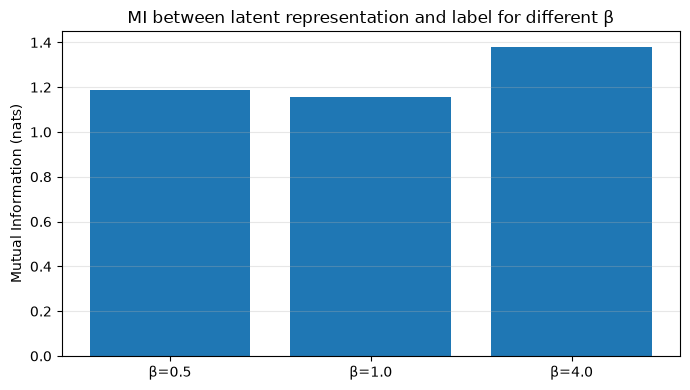

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))

x = np.arange(len(betas))
ax.bar(x, mi_latent_per_beta, label='MI(z, y)')

ax.set_xticks(x)
ax.set_xticklabels([f'β={b}' for b in betas])
ax.set_ylabel('Mutual Information (nats)')
ax.set_title('MI between latent representation and label for different β')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()
pdf.savefig(fig, bbox_inches="tight")
pdf.close()
